# 10 · Independent validation against Canadian airborne lidar (NRCan CanElevation, 2019–2025)

**Question:** do the reclassified 30 m heights hold up across the **Canadian boreal**, from Yukon to Newfoundland, against
1 m airborne lidar flown in the same years as ICESat-2?

**Reference data:** NRCan's CanElevation HRDEM lidar collection (open, STAC: `datacube.services.geo.ca`): one item per
provincial / territorial / federal lidar project, each with a 1 m surface model (DSM, first returns) and terrain model
(DTM). **Canopy height = DSM − DTM**, the same 1 m canopy height model approach as the G-LiHT validation (notebook 05). The
files are cloud-optimised GeoTIFFs, so only the boxes we need are read.

**Why this is a real test:** none of these sites were used to develop configs v0.1–v0.6. Results are reported per province
or territory.

**Reference height of a segment:** RH98 of the 1 m canopy height model inside the segment footprint (30 m along track ×
11 m), as in notebook 05. No horizontal shift is applied (notebook 05's shift scan showed it does not change the result).

**Caveats:** some projects were flown leaf-off (spring or autumn), which lowers DSM heights of deciduous canopy; the
acquisition month is kept, and results are also shown for leaf-on (June–September) projects only. DSM − DTM is a
first-return canopy surface; it can include buildings and power lines (city projects are excluded).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")
CFGS = {"v0.5": ipl.load_config(REPO / "config" / "atl03_reclass_v0.5.yaml"), "v0.6": cfg}   # v0.4: runs/v0.5; v0.3: runs/v0.4; v0.2: runs/v0.3
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
CE = WORK / "canelevation"; (CE / "photons").mkdir(parents=True, exist_ok=True); (CE / "chm").mkdir(exist_ok=True)
OUT = RUN / "validation_canelevation"; OUT.mkdir(exist_ok=True)
print("configs", {k: c["config_sha1"] for k, c in CFGS.items()}, "| run_dir:", RUN)

configs {'v0.5': 'f419941dbc72', 'v0.6': '40e8f82a4112'} | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.6


## 1 · Which lidar projects, and which boxes inside them

**What happens:** list every CanElevation lidar project from 2019–2025 between 50° and 70° N; keep those overlapping boreal
tiles (city projects excluded); pick up to `N_PER_PROVINCE` projects per province / territory at random (fixed seed), and
`BOXES_PER_PROJECT` boxes of `BOX_KM` × `BOX_KM` at random points inside each project. Only these boxes are read and used.

**Output:** `validation_canelevation/boxes.parquet` and a map.

In [2]:
N_PER_PROVINCE, BOXES_PER_PROJECT, BOX_KM = 3, 2, 4.0
YEARS = range(2019, 2026)
proj = ref.canelevation_items([-141, 50, -52, 70], min_year=min(YEARS))
proj = proj[proj.year.isin(YEARS) & ~proj.prefix.str.startswith("VILLE")]
tiles = gpd.read_file(cfg["paths"]["boreal_tiles"])
j = gpd.sjoin(proj[["id", "geometry"]].to_crs(tiles.crs), tiles[["tile_num", "geometry"]], predicate="intersects")
proj = proj[proj.id.isin(j.id)]
pick = pd.concat([g.sample(min(N_PER_PROVINCE, len(g)), random_state=0) for _, g in proj.groupby("prefix")])
rng = np.random.default_rng(0)
boreal = tiles.to_crs(4326).union_all()
rows = []
for r in pick.itertuples():
    area = r.geometry.intersection(boreal)
    if area.is_empty:
        continue
    lam = gpd.GeoSeries([area], crs=4326).to_crs(3979).iloc[0]
    minx, miny, maxx, maxy = lam.bounds
    k, tries = 0, 0
    while k < BOXES_PER_PROJECT and tries < 200:
        tries += 1
        x, y = rng.uniform(minx, maxx), rng.uniform(miny, maxy)
        b = box(x - BOX_KM * 500, y - BOX_KM * 500, x + BOX_KM * 500, y + BOX_KM * 500)
        if lam.contains(b):
            rows.append({"box_id": f"{r.id}_{k}", "project": r.id, "prefix": r.prefix, "year": r.year, "month": r.month,
                         "dsm": r.dsm, "dtm": r.dtm, "geometry": gpd.GeoSeries([b], crs=3979).to_crs(4326).iloc[0]})
            k += 1
boxes = gpd.GeoDataFrame(rows, crs=4326)
boxes["leaf_on"] = boxes.month.between(6, 9)
boxes.to_parquet(OUT / "boxes.parquet")
print(f"{len(proj)} boreal lidar projects 2019-2024; picked {len(pick)}; {len(boxes)} boxes")
boxes.groupby("prefix").agg(boxes=("box_id", "size"), years=("year", lambda s: sorted(set(s))), leaf_on=("leaf_on", "mean"))

310 boreal lidar projects 2019-2024; picked 36; 57 boxes


,boxes,years,leaf_on
prefix,,,
AB,6,"[2022, 2023]",0.333333
BC,4,[2020],0.500000
CGP,2,[2022],1.000000
DUC,4,"[2022, 2023]",0.000000
MB,6,"[2019, 2021, 2024]",0.333333
NL,2,[2019],1.000000
NRCAN,5,"[2019, 2022, 2023]",0.400000
NWT,6,"[2020, 2021]",0.666667
ON,6,"[2021, 2024]",0.333333


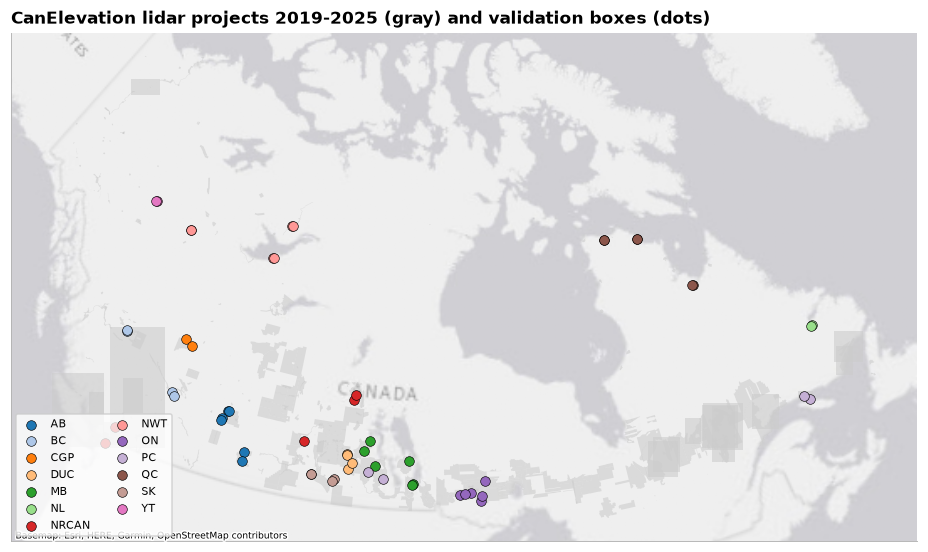

In [3]:
# Map: selected boxes by province / territory (Canada Lambert, ESRI Light Gray basemap)
CRS = 3979
fig, ax = plt.subplots(figsize=(12, 6))
proj.to_crs(CRS).plot(ax=ax, color="0.8", lw=0, alpha=0.6, zorder=2)
cmap = plt.get_cmap("tab20")
for i, (p, g) in enumerate(boxes.groupby("prefix")):
    c = g.to_crs(CRS).geometry.centroid
    ax.scatter(c.x, c.y, s=40, color=cmap(i % 20), edgecolor="k", lw=0.4, zorder=4, label=p)
ps.add_basemap(ax, CRS); ps.map_axes(ax, "CanElevation lidar projects 2019-2025 (gray) and validation boxes (dots)")
ax.legend(ncol=2, loc="lower left", frameon=True, fontsize=7)
fig.savefig(FIG / "10_canelevation_map.png")

## 2 · Canopy height models for the boxes, and ICESat-2 photons over them

**What happens, per box:** (1) read the DSM and DTM windows from the remote COGs and write a local 1 m canopy height model;
(2) find the ATL03 v007 granules of June–September of the lidar year crossing the box and fetch every photon in it, plus the
ATL08 · PhoREAL (today) 30 m segments. Both are cached in the shared work folder.

In [4]:
sliderule = ipl.sliderule_init()
log = []
for r in boxes.itertuples():
    rec = {"box_id": r.box_id}
    try:
        chm = ref.canelevation_chm(r.dsm, r.dtm, r.geometry, CE / "chm" / f"{r.box_id}.tif")
        rec["chm"] = chm
        if chm is None:
            rec["status"] = "no lidar data in box"; log.append(rec); continue
        fn, fpr = CE / "photons" / f"{r.box_id}.parquet", CE / "photons" / f"{r.box_id}_phoreal.parquet"
        if fn.exists():
            rec["status"] = "cached"; log.append(rec); continue
        grs = ipl.granules_from_cmr(r.geometry, [r.year], cfg["icesat2"]["months"], release=cfg["icesat2"]["release"])
        if not grs:
            rec["status"] = "no granules"; log.append(rec); continue
        ph = ipl.fetch_photons(r.geometry, grs, cfg)
        if not len(ph):
            rec["status"] = "no photons"; log.append(rec); continue
        ipl.write_parquet(ph.assign(box_id=r.box_id, prefix=r.prefix), fn, ipl.provenance(cfg, box_id=r.box_id, granules=grs))
        pr = ipl.fetch_phoreal(r.geometry, grs, cfg)
        if len(pr):
            ipl.write_parquet(pr, fpr, ipl.provenance(cfg, box_id=r.box_id))
        rec.update({"status": "fetched", "granules": len(grs), "photons": len(ph), "tracks": ph.track_id.nunique()})
    except Exception as e:
        rec["status"] = f"error: {type(e).__name__}: {str(e)[:120]}"
    log.append(rec)
log = pd.DataFrame(log); log.to_csv(OUT / "fetch_log.csv", index=False)
log.status.str.split(":").str[0].value_counts()

(dataframe.lua:210) <AppServer.41665> produced an empty dataframe


(dataframe.lua:210) <AppServer.41721> produced an empty dataframe


(dataframe.lua:210) <AppServer.41895> produced an empty dataframe


(dataframe.lua:210) <AppServer.42041> produced an empty dataframe


(dataframe.lua:210) <AppServer.42056> produced an empty dataframe


status
cached                  48
no photons               5
no lidar data in box     4
Name: count, dtype: int64

## 3 · Segments for every version, and the lidar reference height in each footprint

In [5]:
fn = OUT / "segments_canelevation.parquet"
if fn.exists():
    segs = gpd.read_parquet(fn)
else:
    parts = []
    ok = log[log.status.isin(["fetched", "cached"])]
    for r in boxes[boxes.box_id.isin(ok.box_id)].itertuples():
        try:
            ph = gpd.read_parquet(CE / "photons" / f"{r.box_id}.parquet")
            fpr = CE / "photons" / f"{r.box_id}_phoreal.parquet"
            pr = gpd.read_parquet(fpr) if fpr.exists() else None
            s = val.segments_all_versions(ph, CFGS, cfg, pr)
            fps = ref.segment_footprints(s, cfg["validation"]["segment_footprint_width_m"])
            a = ref.als_segment_metrics(fps, [str(CE / "chm" / f"{r.box_id}.tif")], 0.0, 0.0, percentiles=(90, 95, 98, 100))
            a = gpd.GeoDataFrame(a, crs=fps.crs).to_crs(4326)
            parts.append(a.assign(box_id=r.box_id, prefix=r.prefix, lidar_year=r.year, lidar_month=r.month, leaf_on=r.leaf_on))
        except Exception as e:
            print(r.box_id, "failed:", type(e).__name__, str(e)[:150])
    segs = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=4326)
    ipl.write_parquet(segs, fn, ipl.provenance(cfg, configs={k: c["config_sha1"] for k, c in CFGS.items()}))
segs = segs[segs.als_n > 0].copy()
segs["light"] = np.where(segs.solar_elevation > 0, "day", "night")
segs["beam"] = np.where(segs.strong, "strong", "weak")
segs["region"] = segs.prefix
segs.groupby("region").agg(segments=("seg", "size"), boxes=("box_id", "nunique"), lidar_rh98_median=("als_rh98", "median"),
                           leaf_on=("leaf_on", "mean"), day_share=("light", lambda s: (s == "day").mean())).round(2)

NL-Churchill_2019-1m_0 failed: KeyError 'lon'


,segments,boxes,lidar_rh98_median,leaf_on,day_share
region,,,,,
AB,2317,5,0.24,0.06,0.60
BC,462,4,8.73,0.84,1.00
CGP,715,2,0.05,1.00,0.62
DUC,1506,4,0.07,0.00,0.77
MB,1108,4,0.03,0.17,0.90
NL,197,1,2.70,1.00,1.00
NRCAN,1065,3,5.19,0.75,0.00
NWT,1522,6,10.15,0.59,0.75
ON,1618,6,13.09,0.27,0.68


## 4 · Results by reference height class and province / territory (common segments)

coverage (share of segments with a height)


,ATL08 · PhoREAL (today),ATL08 · our binning (control),reclassified v0.5,reclassified v0.6
region,,,,
AB,0.97,0.82,0.50,0.50
BC,0.82,0.75,0.45,0.45
CGP,0.95,0.59,0.45,0.45
DUC,0.95,0.71,0.40,0.40
MB,0.98,0.61,0.50,0.50
NL,0.89,0.57,0.59,0.59
NRCAN,0.99,0.75,0.56,0.56
NWT,0.93,0.79,0.57,0.58
ON,0.96,0.84,0.44,0.45


bias  \
version                       ATL08 · PhoREAL (today)   
region      height_class                                
AB          0-1 m                                2.38   
            1-2 m                                3.19   
            10-15 m                             -3.18   
            15-20 m                             -3.69   
            2-5 m                                0.96   
...                                               ...   
all regions 2-5 m                                0.50   
            20+ m                               -4.75   
            5-10 m                              -0.74   
            all                                 -0.34   
            spurious_veg_rate                    0.24   

                                                                               \
version                       ATL08 · our binning (control) reclassified v0.5   
region      height_class                                                        
AB          0-1 m                                      2.41              0.73   
            1-2 m                                      3.28              1.56   
            10-15 m                                   -2.71             -2.25   
            15-20 m                                   -2.55             -0.87   
            2-5 m                                      0.31             -0.57   
...                                                     ...               ...   
all regions 2-5 m                                      0.40             -0.22   
            20+ m                                     -3.05             -3.30   
            5-10 m                                    -0.92             -0.88   
            all                                       -0.06             -0.72   
            spurious_veg_rate                          0.24              0.07   

                                                                      n  \
version                       reclassified v0.6 ATL08 · PhoREAL (today)   
region      height_class                                                  
AB          0-1 m                          0.74                   574.0   
            1-2 m                          1.55                    50.0   
            10-15 m                       -2.25                    70.0   
            15-20 m                       -0.74                    53.0   
            2-5 m                         -0.56                    90.0   
...                                         ...                     ...   
all regions 2-5 m                         -0.23                   618.0   
            20+ m                         -2.94                   463.0   
            5-10 m                        -0.85                   893.0   
            all                           -0.64                  5268.0   
            spurious_veg_rate              0.07                  2025.0   

                                                                               \
version                       ATL08 · our binning (control) reclassified v0.5   
region      height_class                                                        
AB          0-1 m                                     574.0             574.0   
            1-2 m                                      50.0              50.0   
            10-15 m                                    70.0              70.0   
            15-20 m                                    53.0              53.0   
            2-5 m                                      90.0              90.0   
...                                                     ...               ...   
all regions 2-5 m                                     618.0             618.0   
            20+ m                                     463.0             463.0   
            5-10 m                                    893.0             893.0   
            all                                      5268.0            5268.0   
           

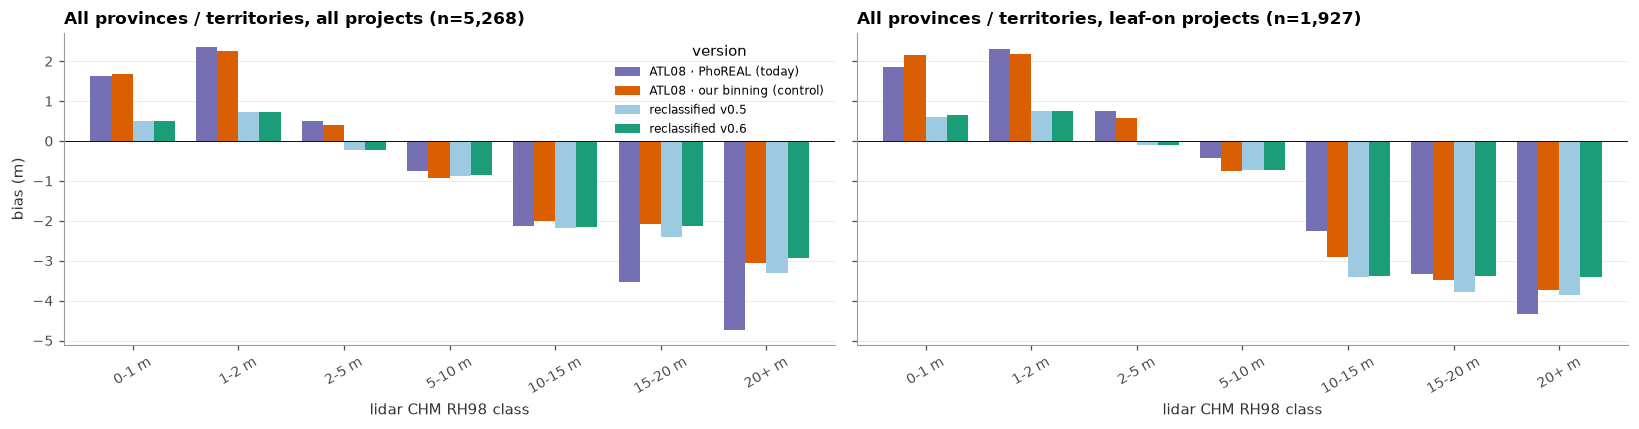

In [6]:
# Version names (17 Oct 2026): whose photon classes · who made the 30 m segments. All use ATL03 release 007 photons.
VERS = {val.LABEL_CURRENT: "h_canopy_phoreal", val.LABEL_CHECK: "h_canopy_atl08",
        "reclassified v0.5": "h_canopy_v05", "reclassified v0.6": "h_canopy_v06"}
VCOL = {val.LABEL_CURRENT: val.SCHEME_COLORS[val.LABEL_CURRENT], val.LABEL_CHECK: val.SCHEME_COLORS[val.LABEL_CHECK],
        "reclassified v0.5": "#9ecae1", "reclassified v0.6": val.SCHEME_COLORS[val.LABEL_NEW]}
NEWV = [k for k in VERS if k.startswith("reclassified")]       # candidate versions, oldest first; NEWV[-1] = this config
REF = "als_rh98"
edges = cfg["validation"]["height_classes_m"]
cov = pd.DataFrame({k: segs.groupby("region")[c].apply(lambda s: s.notna().mean()) for k, c in VERS.items()}).round(2)
print("coverage (share of segments with a height)"); display(cov)
common = segs.dropna(subset=list(VERS.values()) + [REF])
rows = []
for (sub, g0) in [("all projects", common), ("leaf-on projects", common[common.leaf_on])]:
    for reg, g in list(g0.groupby("region")) + [("all regions", g0)]:
        for k, c in VERS.items():
            rows.append(val.metrics_by_height_class(g[c], g[REF], edges, cfg["validation"]["spurious_veg"]).assign(region=reg, version=k, subset=sub))
res = pd.concat(rows).reset_index(names="height_class")
res.to_csv(OUT / "canelevation_by_class_region_common.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, sub in zip(axes, ["all projects", "leaf-on projects"]):
    tt = res[(res.region == "all regions") & (res.subset == sub) & ~res.height_class.isin(["all", "spurious_veg_rate"])]
    pv = tt.pivot(index="height_class", columns="version", values="bias").reindex(val.height_class_labels(edges))[list(VERS)]
    pv.plot.bar(ax=ax, rot=30, width=0.8, color=[VCOL[c] for c in pv.columns], legend=(sub == "all projects"))
    ax.axhline(0, c="k", lw=0.6); ax.grid(axis="x", visible=False); ax.set_xlabel("lidar CHM RH98 class"); ax.set_ylabel("bias (m)")
    ax.set_title(f"All provinces / territories, {sub} (n={int(tt[tt.version == NEWV[-1]].n.sum()):,})")
fig.tight_layout(); fig.savefig(FIG / "10_canelevation_bias.png")
res[res.subset == "all projects"].pivot_table(index=["region", "height_class"], columns="version", values=["n", "bias"]).round(2)

In [7]:
# Tall-forest acceptance per region (classes >= 10 m with >= 10 segments) and spurious vegetation
tall = [c for c in val.height_class_labels(edges) if int(c.split("-")[0].split("+")[0]) >= 10]
acc = []
for reg in sorted(common.region.unique()) + ["all regions"]:
    for cl in tall:
        t = res[(res.subset == "all projects") & (res.region == reg) & (res.height_class == cl)].set_index("version")
        if t.empty or t.loc[val.LABEL_CURRENT, "n"] < 10:
            continue
        b7 = t.loc[val.LABEL_CURRENT, "bias"]
        acc.append({"region": reg, "class": cl, "n": int(t.loc[NEWV[-1], "n"]), "bias ATL08 · PhoREAL": b7,
                    **{f"bias {v}": t.loc[v, "bias"] for v in NEWV},
                    **{f"{v} passes": bool(t.loc[v, "bias"] >= b7) for v in NEWV},
                    # restated criterion proposed 16 Oct (pending): |bias| no larger, and not more negative where today underestimates
                    **{f"{v} passes |bias|": bool(abs(t.loc[v, "bias"]) <= abs(b7) and (b7 >= 0 or t.loc[v, "bias"] >= b7)) for v in NEWV}})
acc = pd.DataFrame(acc); acc.to_csv(OUT / "canelevation_tall_acceptance.csv", index=False)
spur = res[(res.subset == "all projects") & (res.height_class == "spurious_veg_rate")].pivot(index="region", columns="version", values="bias")[list(VERS)].round(3)
display(spur.rename_axis(None, axis=1))
acc.round(2)

,ATL08 · PhoREAL (today),ATL08 · our binning (control),reclassified v0.5,reclassified v0.6
region,,,,
AB,0.399,0.408,0.127,0.129
BC,1.000,1.000,0.600,0.600
CGP,0.353,0.311,0.059,0.067
DUC,0.221,0.153,0.058,0.058
MB,0.126,0.122,0.031,0.031
NL,0.000,0.273,0.000,0.000
NRCAN,0.129,0.100,0.043,0.043
NWT,0.000,0.800,0.000,0.000
ON,0.212,0.424,0.030,0.030


,region,class,n,bias ATL08 · PhoREAL,bias reclassified v0.5,bias reclassified v0.6,reclassified v0.5 passes,reclassified v0.6 passes,reclassified v0.5 passes |bias|,reclassified v0.6 passes |bias|
0,AB,10-15 m,70,-3.18,-2.25,-2.25,True,True,True,True
1,AB,15-20 m,53,-3.69,-0.87,-0.74,True,True,True,True
2,AB,20+ m,49,-6.00,-2.93,-2.93,True,True,True,True
3,BC,10-15 m,26,0.60,-0.76,-0.74,False,False,False,False
4,BC,15-20 m,35,-5.01,-2.37,-2.13,True,True,True,True
5,BC,20+ m,36,-13.18,-8.26,-8.32,True,True,True,True
6,CGP,15-20 m,10,-3.48,-2.89,-2.81,True,True,True,True
7,DUC,10-15 m,13,-4.13,-1.40,-1.40,True,True,True,True
8,NL,10-15 m,10,-8.97,-5.75,-5.74,True,True,True,True
9,NRCAN,10-15 m,90,-3.34,-5.51,-5.39,False,False,False,False


n                                \
version        ATL08 · PhoREAL (today) ATL08 · our binning (control)   
stratum                                                                
day · strong                    2952.0                        2952.0   
day · weak                       304.0                         304.0   
night · strong                  1684.0                        1684.0   
night · weak                     328.0                         328.0   

                                                                        r2  \
version        reclassified v0.5 reclassified v0.6 ATL08 · PhoREAL (today)   
stratum                                                                      
day · strong              2952.0            2952.0                    0.69   
day · weak                 304.0             304.0                    0.29   
night · strong            1684.0            1684.0                    0.79   
night · weak               328.0             328.0                    0.75   

                                                                \
version        ATL08 · our binning (control) reclassified v0.5   
stratum                                                          
day · strong                            0.81              0.75   
day · weak                              0.25              0.35   
night · strong                          0.78              0.75   
night · weak                            0.76              0.64   

                                                    bias  \
version        reclassified v0.6 ATL08 · PhoREAL (today)   
stratum                                                    
day · strong                0.77                   -0.49   
day · weak                  0.33                   -0.43   
night · strong              0.75                    0.02   
night · weak                0.64                   -0.80   

                                                                \
version        ATL08 · our binning (control) reclassified v0.5   
stratum                                                          
day · strong                            0.24             -0.29   
day · weak                              1.20             -1.15   
night · strong                         -0.62             -1.13   
night · weak                           -1.05             -2.03   

                                                    rmse  \
version        reclassified v0.6 ATL08 · PhoREAL (today)   
stratum                                                    
day · strong               -0.19                    4.83   
day · weak                 -1.10                    4.19   
night · strong             -1.09                    3.22   
night · weak               -2.01                    2.80   

                                                                \
version        ATL08 · our binning (control) reclassified v0.5   
stratum                                                          
day · strong                            3.78              4.36   
day · weak                              5.02              4.39   
night · strong                          3.30              3.70   
night · weak                            2.86              3.81   

                                  
version        reclassified v0.6  
stratum                           
day · strong                4.22  
day · weak                  4.47  
night · strong              3.69  
night · weak                3.79

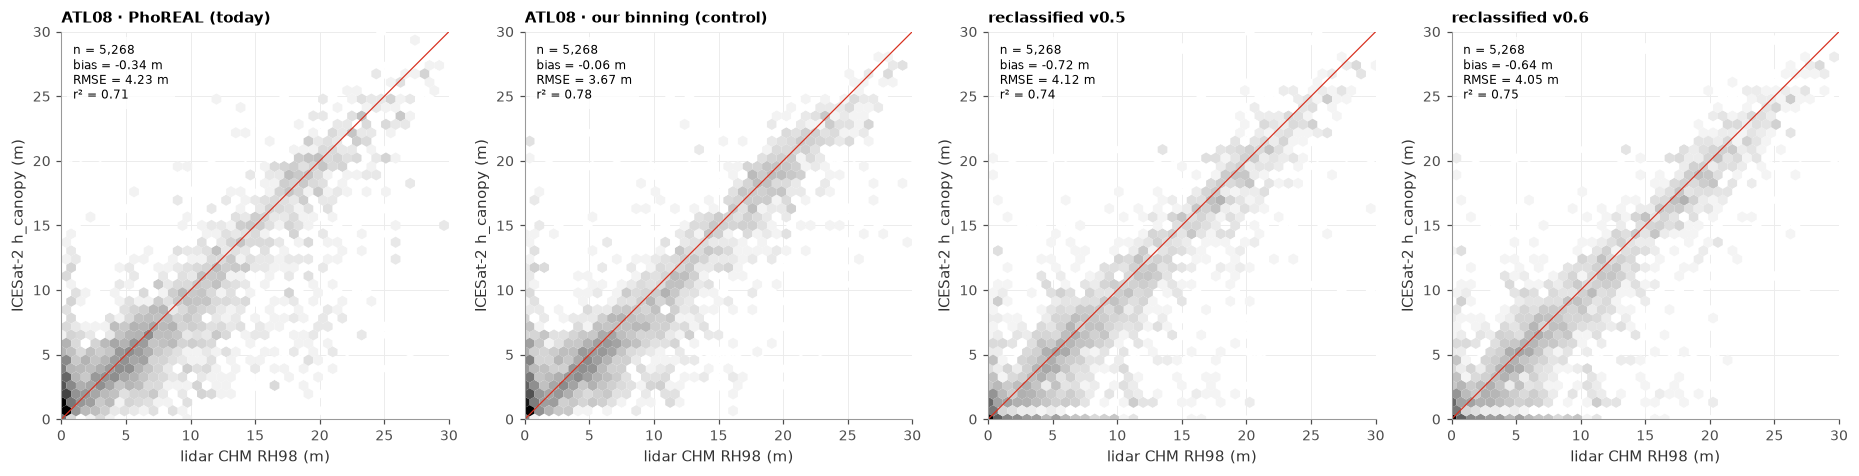

In [8]:
common = common.assign(signal_stratum=common.light + " · " + common.beam)
rows = []
for st, g in common.groupby("signal_stratum"):
    for k, c in VERS.items():
        e = g[c] - g[REF]
        rows.append({"stratum": st, "version": k, "n": len(g), "bias": e.mean(), "rmse": np.sqrt((e ** 2).mean()), "r2": val.r_squared(g[c], g[REF])})
sig = pd.DataFrame(rows); sig.to_csv(OUT / "canelevation_by_signal.csv", index=False)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
for ax, (k, c) in zip(axes, VERS.items()):
    val.plot_scatter(ax, common[c], common[REF], k, lim=30); ax.set_xlabel("lidar CHM RH98 (m)")
fig.tight_layout(); fig.savefig(FIG / "10_canelevation_scatter.png")
sig.pivot(index="stratum", columns="version", values=["n", "r2", "bias", "rmse"]).round(2)

### Zeros and non-zero accuracy by reference height class
**Why:** a 0 m height is right over bare ground (reference below ~1 m) and wrong over vegetation (above ~2 m). Mean bias
rewards writing 0 m, so it is read together with the share of zeros per class and the accuracy of the non-zero heights
(LOG, 16 Oct 2026). Common segments (every version reports a height).

zero_share                                \
version      ATL08 · PhoREAL (today) ATL08 · our binning (control)   
height_class                                                         
0-1 m                           0.03                           0.0   
1-2 m                           0.01                           0.0   
2-5 m                           0.01                           0.0   
5-10 m                          0.00                           0.0   
10-15 m                         0.00                           0.0   
15-20 m                         0.00                           0.0   
20+ m                           0.00                           0.0   

                                                            bias_nonzero  \
version      reclassified v0.5 reclassified v0.6 ATL08 · PhoREAL (today)   
height_class                                                               
0-1 m                     0.80              0.80                    1.67   
1-2 m                     0.40              0.40                    2.37   
2-5 m                     0.20              0.21                    0.55   
5-10 m                    0.10              0.10                   -0.72   
10-15 m                   0.02              0.02                   -2.11   
15-20 m                   0.01              0.01                   -3.52   
20+ m                     0.00              0.00                   -4.75   

                                                                                
version      ATL08 · our binning (control) reclassified v0.5 reclassified v0.6  
height_class                                                                    
0-1 m                                 1.69              2.94              2.98  
1-2 m                                 2.25              2.24              2.24  
2-5 m                                 0.40              0.53              0.55  
5-10 m                               -0.92             -0.21             -0.16  
10-15 m                              -2.00             -2.03             -1.99  
15-20 m                              -2.09             -2.20             -1.92  
20+ m                                -3.05             -3.30             -2.94

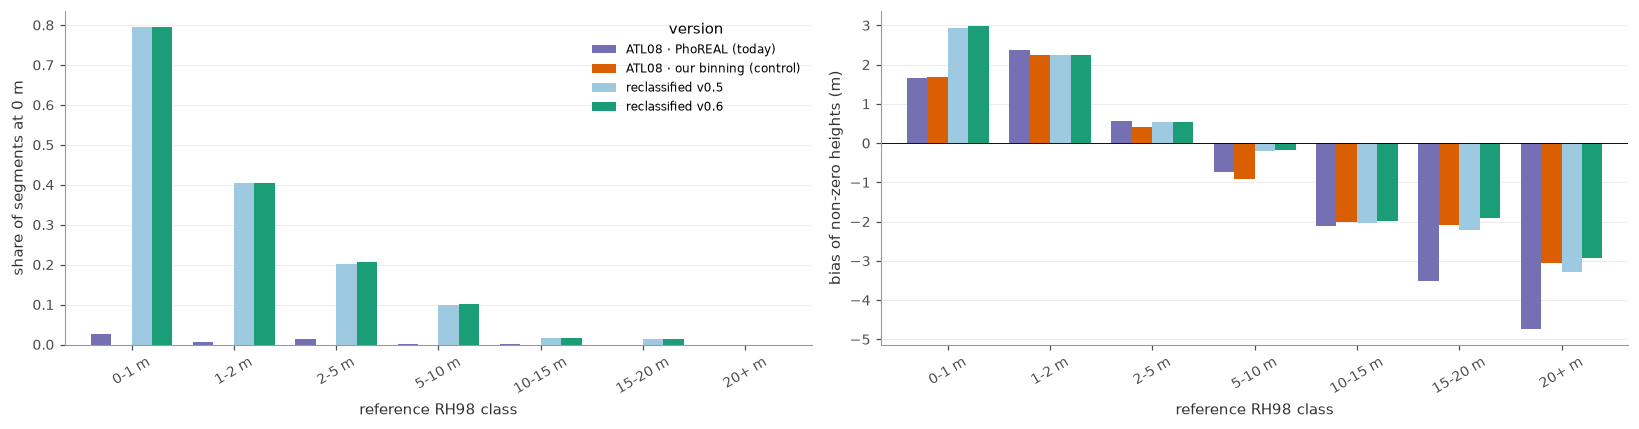

In [9]:
rows = []
for k, c in VERS.items():
    rows.append(val.zeros_by_height_class(common[c], common[REF], edges).assign(version=k))
zt = pd.concat(rows).reset_index(names="height_class")
zt.to_csv(OUT / "canelevation_zeros_by_class.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, m, lab in [(axes[0], "zero_share", "share of segments at 0 m"), (axes[1], "bias_nonzero", "bias of non-zero heights (m)")]:
    pv = zt.pivot(index="height_class", columns="version", values=m).reindex(val.height_class_labels(edges))[list(VERS)]
    pv.plot.bar(ax=ax, rot=30, width=0.8, color=[VCOL[c] for c in pv.columns], legend=(m == "zero_share"))
    ax.axhline(0, c="k", lw=0.6); ax.grid(axis="x", visible=False); ax.set_ylabel(lab); ax.set_xlabel("reference RH98 class")
fig.tight_layout(); fig.savefig(FIG / "10_zeros_by_class.png")
zt.pivot(index="height_class", columns="version", values=["zero_share", "bias_nonzero"]).reindex(val.height_class_labels(edges)).round(2)

### By terrain slope
**Why:** v0.4 widens the ground window with the along-track ground slope (an 11 m footprint on a slope returns ground
over metres of height). Bias per slope class shows whether that removed the false vegetation on slopes without hurting
flat ground. Slope = along-track ground slope from the v0.6 ground surface (circumpolar-consistent; across-track slope
not known from one beam).

In [10]:
common = common.assign(slope_class=pd.cut(common["ground_slope_deg_v06"], [0, 5, 10, 20, 90], right=False,
                                          labels=["0-5°", "5-10°", "10-20°", "> 20°"]))
common["veg_class"] = np.where(common[REF] < 1, "reference < 1 m", np.where(common[REF] < 5, "1-5 m", "≥ 5 m"))
rows = []
for (sc, vc), g in common.groupby(["slope_class", "veg_class"], observed=True):
    for k, c in VERS.items():
        e = g[c] - g[REF]
        rows.append({"slope": sc, "reference": vc, "version": k, "n": len(g), "bias": e.mean(),
                     "spurious": ((g[REF] < 1) & (g[c] > 2)).sum() / max(1, (g[REF] < 1).sum())})
st = pd.DataFrame(rows); st.to_csv(OUT / "canelevation_by_slope.csv", index=False)
st.pivot_table(index=["reference", "slope"], columns="version", values=["n", "bias"], observed=True).round(2)

bias                                \
version                ATL08 · PhoREAL (today) ATL08 · our binning (control)   
reference       slope                                                          
1-5 m           0-5°                      0.61                          0.54   
                10-20°                    4.15                          3.28   
                5-10°                     2.75                          2.22   
                > 20°                     7.98                          8.16   
reference < 1 m 0-5°                      1.46                          1.52   
                10-20°                    8.61                          9.04   
                5-10°                     5.10                          5.07   
                > 20°                     9.30                          9.60   
≥ 5 m           0-5°                     -2.40                         -1.84   
                10-20°                   -2.51                         -1.49   
                5-10°                    -2.24                         -1.48   
                > 20°                    -3.06                         -2.70   

                                                            \
version                reclassified v0.5 reclassified v0.6   
reference       slope                                        
1-5 m           0-5°               -0.12             -0.12   
                10-20°              2.57              2.53   
                5-10°               0.88              0.90   
                > 20°               0.68              0.41   
reference < 1 m 0-5°                0.40              0.41   
                10-20°              6.35              6.34   
                5-10°               2.87              2.90   
                > 20°               3.62              3.62   
≥ 5 m           0-5°               -1.93             -1.81   
                10-20°             -2.07             -1.41   
                5-10°              -1.62             -1.48   
                > 20°              -3.82             -3.81   

                                             n                                \
version                ATL08 · PhoREAL (today) ATL08 · our binning (control)   
reference       slope                                                          
1-5 m           0-5°                     744.0                         744.0   
                10-20°                    22.0                          22.0   
                5-10°                     27.0                          27.0   
                > 20°                     18.0                          18.0   
reference < 1 m 0-5°                    1962.0                        1962.0   
                10-20°                     8.0                           8.0   
                5-10°                     37.0                          37.0   
                > 20°                     18.0                          18.0   
≥ 5 m           0-5°                    2071.0                        2071.0   
                10-20°                   123.0                         123.0   
                5-10°                    176.0                         176.0   
                > 20°                     62.0                          62.0   

                                                            
version                reclassified v0.5 reclassified v0.6  
reference       slope                                       
1-5 m           0-5°               744.0             744.0  
                10-20°              22.0              22.0  
                5-10°               27.0              27.0  
                > 20°               18.0              18.0  
reference < 1 m 0-5°              1962.0            1962.0  
                10-20°               8.0               8.0  
                5-10°               37.0              37.0  
                > 20°               18.0              18.0  
≥ 5 m           0-5°              2071

## Results (config v0.6, 18 October 2026)

CanElevation is the main independent reference (discrete-return lidar, 13 provinces / territories, never used to build any version).
- **Tall-forest acceptance, all regions:** 15–20 m today −3.52 → v0.6 −2.13 m; 20 m+ −4.75 → −2.94 m (pass); 10–15 m −2.13 →
  −2.15 m (equal; fails by 0.02 m). v0.6 recovers most of v0.5's tall-forest loss (v0.5: −2.41, −3.30 m).
- **By region:** passes in AB, BC (15 m+), CGP, DUC, NL, ON, PC and YT, often by 1–5 m (BC 20 m+ −13.2 → −8.3 m; PC 20 m+
  −5.9 → −1.0 m). Fails in NRCAN (10–20 m, −3.3 / −4.9 → −5.4 / −11.7 m; 128 segments), NWT (0.5–0.6 m more negative) and
  BC 10–15 m: dense or open northern stands where the ground can start on a canopy layer (LOG 18 Oct).
- **Short vegetation and slopes:** on 0–5° slopes spurious vegetation over < 1 m falls 22 → 6 % and the bias +1.46 → +0.41 m;
  forest ≥ 5 m bias improves at every slope class (10–20°: −2.5 → −1.4 m).
- **Overall (same segments):** r² 0.73 → 0.77, RMSE 3.87 → 3.65 m, spurious vegetation 14 → 4 %, forest called bare 1 → 5 %,
  coverage 94 → 51 % (acceptable).